In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('ecommerce_sales_analytics_5000.csv')

df.head()

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
0,10001,1/1/2022,1102,Beauty,South,7,373.65,0.28,Wallet,10,4.7,1883.20
1,10002,1/2/2022,1435,Clothing,South,7,47.74,0.09,Card,6,3.9,304.10
2,10003,1/3/2022,1860,Beauty,East,3,311.28,0.31,COD,6,2.5,644.35
3,10004,1/4/2022,1270,Electronics,West,5,524.47,0.02,Wallet,6,1.6,2569.90
4,10005,1/5/2022,1106,Clothing,West,5,139.87,0.33,Wallet,4,4.9,468.56


In [12]:
df.shape
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          5000 non-null   int64  
 1   order_date        5000 non-null   object 
 2   customer_id       5000 non-null   int64  
 3   product_category  5000 non-null   object 
 4   region            5000 non-null   object 
 5   quantity          5000 non-null   int64  
 6   unit_price        5000 non-null   float64
 7   discount          5000 non-null   float64
 8   payment_method    5000 non-null   object 
 9   delivery_days     5000 non-null   int64  
 10  customer_rating   5000 non-null   float64
 11  revenue           5000 non-null   float64
dtypes: float64(4), int64(4), object(4)
memory usage: 468.9+ KB


,order_id,customer_id,quantity,unit_price,discount,delivery_days,customer_rating,revenue
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,12500.500000,1505.701200,4.044800,308.418774,0.179984,6.118800,2.973980,1021.955148
std,1443.520003,290.836902,2.020398,169.259369,0.101404,3.153264,1.157722,825.584219
min,10001.000000,1000.000000,1.000000,15.150000,0.000000,1.000000,1.000000,11.210000
25%,11250.750000,1253.000000,2.000000,161.895000,0.090000,3.000000,2.000000,354.527500
50%,12500.500000,1510.000000,4.000000,309.890000,0.180000,6.000000,3.000000,796.650000
75%,13750.250000,1761.000000,6.000000,455.557500,0.270000,9.000000,4.000000,1515.690000
max,15000.000000,1999.000000,7.000000,599.960000,0.350000,11.000000,5.000000,4119.330000


In [13]:
df.columns

Index(['order_id', 'order_date', 'customer_id', 'product_category', 'region',
       'quantity', 'unit_price', 'discount', 'payment_method', 'delivery_days',
       'customer_rating', 'revenue'],
      dtype='object')

In [14]:
df.nunique()

order_id            5000
order_date          5000
customer_id          989
product_category       4
region                 4
quantity               7
unit_price          4788
discount              36
payment_method         3
delivery_days         11
customer_rating       41
revenue             4940
dtype: int64

In [15]:
df.isna().sum()

order_id            0
order_date          0
customer_id         0
product_category    0
region              0
quantity            0
unit_price          0
discount            0
payment_method      0
delivery_days       0
customer_rating     0
revenue             0
dtype: int64

In [16]:
df.duplicated().sum()

0

In [17]:
df["order_date"] = pd.to_datetime(df["order_date"])

In [18]:
df["order_date"].dtype

dtype('<M8[ns]')

In [19]:
df[df["quantity"] <= 0]

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue


In [20]:
df[df["unit_price"] <= 0]

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue


In [21]:
df["discount"].min()
df["discount"].max()

0.35

In [22]:
df["customer_rating"].min()

1.0

In [23]:
df["customer_rating"].max()

5.0

In [24]:
df[df["delivery_days"] <= 0]

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue


In [25]:
revenue_summary = df["revenue"].agg(["sum", "mean"])
print(revenue_summary)

sum     5.109776e+06
mean    1.021955e+03
Name: revenue, dtype: float64


In [26]:
df.groupby("product_category")["revenue"].max()

product_category
Beauty         4005.93
Clothing       3928.63
Electronics    4119.33
Home           3640.56
Name: revenue, dtype: float64

In [27]:
df.groupby("product_category")["revenue"].sum()

product_category
Beauty          765860.88
Clothing       1531931.72
Electronics    1829899.22
Home            982083.92
Name: revenue, dtype: float64

In [28]:
df.groupby("region")["revenue"].sum().sort_values(ascending=False)

region
West     1345582.16
North    1281508.45
South    1246640.90
East     1236044.23
Name: revenue, dtype: float64

In [29]:
region_revenue = df.groupby("region")["revenue"].sum()

region_percentage = (region_revenue / region_revenue.sum()) * 100
print(region_percentage)

region
East     24.189794
North    25.079544
South    24.397174
West     26.333488
Name: revenue, dtype: float64


In [30]:
df.groupby("region")["revenue"].mean().sort_values(ascending=False)

region
West     1043.896168
South    1031.987500
East     1007.371011
North    1004.316967
Name: revenue, dtype: float64

In [31]:
df.groupby("region")["order_id"].count()

region
East     1227
North    1276
South    1208
West     1289
Name: order_id, dtype: int64

In [32]:
category_summary = df.groupby("product_category").agg({
    "revenue": ["sum", "mean"],
    "order_id": "count"
})

print(category_summary)

                     revenue              order_id
                         sum         mean    count
product_category                                  
Beauty             765860.88  1059.281992      723
Clothing          1531931.72  1000.608570     1531
Electronics       1829899.22  1029.768835     1777
Home               982083.92  1013.502497      969


In [33]:
df["discount"].corr(df["revenue"])

-0.13929560296730728

In [34]:
df["discount_group"] = pd.cut(
    df["discount"],
    bins=[-0.01, 0.10, 0.20, 0.30, 0.35],
    labels=["0-10%", "10-20%", "20-30%", "30-35%"]
)
df.groupby("discount_group", observed=True)["revenue"].mean()

discount_group
0-10%     1159.461028
10-20%    1057.956481
20-30%     943.936385
30-35%     841.065172
Name: revenue, dtype: float64

In [35]:
df.groupby(["product_category", "discount_group"])["revenue"].mean()

C:\Users\pc\AppData\Local\Temp\ipykernel_20160\99282340.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(["product_category", "discount_group"])["revenue"].mean()


product_category  discount_group
Beauty            0-10%             1262.829067
                  10-20%            1086.217678
                  20-30%             938.856923
                  30-35%             871.995510
Clothing          0-10%             1118.800171
                  10-20%            1000.156659
                  20-30%             976.917575
                  30-35%             827.218565
Electronics       0-10%             1184.213938
                  10-20%            1046.965355
                  20-30%             942.804402
                  30-35%             844.982199
Home              0-10%             1103.454091
                  10-20%            1148.540232
                  20-30%             889.955507
                  30-35%             833.759527
Name: revenue, dtype: float64

In [36]:
df.groupby("discount_group", observed=True).size()

discount_group
0-10%     1401
10-20%    1401
20-30%    1502
30-35%     696
dtype: int64

In [37]:
df["discount"].corr(df["unit_price"])

0.013215363531688337

In [38]:
df["discount"].corr(df["quantity"])

-0.004302402245146645

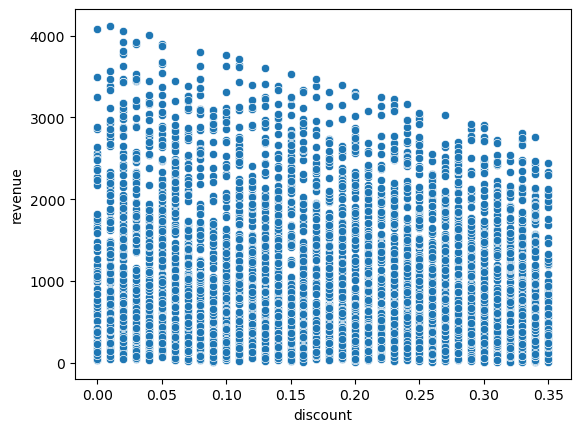

In [39]:
sns.scatterplot(data=df, x="discount", y="revenue")
plt.show()

In [40]:
df.groupby("discount_group", observed=True)["quantity"].mean()

discount_group
0-10%     4.014276
10-20%    4.067809
20-30%    4.072570
30-35%    4.000000
Name: quantity, dtype: float64

In [41]:
df["customer_id"].nunique()

989

In [42]:
df.groupby("customer_id")["revenue"].sum().nlargest(10)

customer_id
1663    17680.69
1955    16265.15
1675    15036.46
1276    15023.71
1647    14894.97
1804    14330.98
1193    14151.65
1836    14110.78
1957    13956.95
1735    13146.25
Name: revenue, dtype: float64

In [43]:
customer_summary = df.groupby("customer_id").agg({
    "revenue": "sum",
    "order_id": "count"
})

customer_summary.sort_values("revenue", ascending=False).head(10)

,revenue,order_id
customer_id,,
1663,17680.69,14
1955,16265.15,10
1675,15036.46,11
1276,15023.71,11
1647,14894.97,11
1804,14330.98,10
1193,14151.65,7
1836,14110.78,9
1957,13956.95,12


In [44]:
customer_summary = df.groupby("customer_id").agg({
    "revenue": "sum",
    "order_id": "count"
})

customer_summary["avg_order_revenue"] = (
    customer_summary["revenue"] / customer_summary["order_id"]
)

top_10 = customer_summary.sort_values(
    "revenue",
    ascending=False
).head(10)

print(top_10)

              revenue  order_id  avg_order_revenue
customer_id                                       
1663         17680.69        14        1262.906429
1955         16265.15        10        1626.515000
1675         15036.46        11        1366.950909
1276         15023.71        11        1365.791818
1647         14894.97        11        1354.088182
1804         14330.98        10        1433.098000
1193         14151.65         7        2021.664286
1836         14110.78         9        1567.864444
1957         13956.95        12        1163.079167
1735         13146.25         8        1643.281250


In [45]:
df["month"] = df["order_date"].dt.to_period("M")

monthly_revenue = (
    df.groupby("month")["revenue"]
      .sum()
      .sort_index()
)

print(monthly_revenue)

month
2022-01    35624.89
2022-02    29908.89
2022-03    30309.28
2022-04    30781.96
2022-05    41629.24
             ...   
2035-05    33393.87
2035-06    25205.26
2035-07    23944.48
2035-08    29354.74
2035-09     4952.23
Freq: M, Name: revenue, Length: 165, dtype: float64


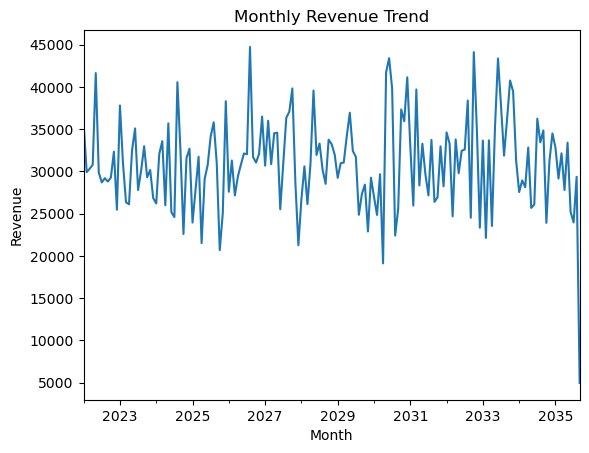

In [46]:
monthly_revenue.plot(kind="line")

plt.xlabel("Month")
plt.ylabel("Revenue")
plt.title("Monthly Revenue Trend")
plt.show()

In [47]:
df.groupby(df["order_date"].dt.year)["revenue"].sum()

order_date
2022    371824.30
2023    365915.79
2024    363209.13
2025    349802.33
2026    386369.69
2027    386151.91
2028    376844.80
2029    359239.24
2030    387884.46
2031    365250.83
2032    386584.63
2033    408725.72
2034    363239.55
2035    238733.36
Name: revenue, dtype: float64

In [48]:
df.groupby(df["order_date"].dt.month_name())["revenue"].mean()

order_date
April         949.321810
August       1061.923456
December      994.258462
February     1047.823392
January       982.430691
July         1015.139908
June         1054.622810
March         979.379078
May          1105.466705
November     1052.968923
October      1012.092109
September    1008.441378
Name: revenue, dtype: float64

In [49]:
orders_per_customer = df.groupby("customer_id")["order_id"].count()

one_time = (orders_per_customer == 1).sum()
repeat = (orders_per_customer > 1).sum()

print("One-time customers:", one_time)
print("Repeat customers:", repeat)

One-time customers: 39
Repeat customers: 950


In [50]:
customer_type = orders_per_customer.map(
    lambda x: "One-time" if x == 1 else "Repeat"
)

df["customer_type"] = df["customer_id"].map(customer_type)

revenue_by_customer_type = (
    df.groupby("customer_type")["revenue"]
      .sum()
      .sort_values(ascending=False)
)

print(revenue_by_customer_type)

customer_type
Repeat      5072972.55
One-time      36803.19
Name: revenue, dtype: float64


In [51]:
df.groupby("product_category")["quantity"].sum()

product_category
Beauty         2995
Clothing       6171
Electronics    7109
Home           3949
Name: quantity, dtype: int64

In [52]:
df.groupby("product_category")["unit_price"].mean().sort_values(ascending=False)

product_category
Electronics    314.902656
Home           306.257730
Beauty         304.712891
Clothing       304.010901
Name: unit_price, dtype: float64

In [53]:
payment_summary = df.groupby("payment_method").agg({
    "revenue": "sum",
    "order_id": "count"
})

print(payment_summary)

                   revenue  order_id
payment_method                      
COD             1788408.44      1774
Card            2366248.20      2270
Wallet           955119.10       956


In [54]:
df.groupby("payment_method")["revenue"].mean().sort_values(ascending=False)

payment_method
Card      1042.400088
COD       1008.122007
Wallet     999.078556
Name: revenue, dtype: float64

In [55]:
pd.crosstab(df["region"], df["payment_method"])

payment_method,COD,Card,Wallet
region,,,
East,461,548,218
North,429,601,246
South,438,526,244
West,446,595,248


In [56]:
df["delivery_days"].corr(df["customer_rating"])

-0.01762494227644023

In [57]:
df.groupby("delivery_days")["customer_rating"].mean()

delivery_days
1     2.988636
2     2.935849
3     2.931463
4     3.071308
5     3.044310
6     2.963617
7     3.024632
8     2.985501
9     2.953846
10    2.924593
11    2.890364
Name: customer_rating, dtype: float64

In [58]:
df.groupby("product_category")["customer_rating"].mean().sort_values(ascending=False)

product_category
Beauty         3.008990
Clothing       3.005095
Electronics    2.951097
Home           2.940660
Name: customer_rating, dtype: float64

In [59]:
df.corr(numeric_only=True)


,order_id,customer_id,quantity,unit_price,discount,delivery_days,customer_rating,revenue
order_id,1.000000,0.017504,-0.003368,0.017876,0.011110,0.006196,0.004984,0.009681
customer_id,0.017504,1.000000,0.023097,0.009748,-0.012617,-0.017440,0.020302,0.025499
quantity,-0.003368,0.023097,1.000000,0.001498,-0.004302,-0.008748,0.019168,0.623564
unit_price,0.017876,0.009748,0.001498,1.000000,0.013215,0.015623,0.005025,0.678032
discount,0.011110,-0.012617,-0.004302,0.013215,1.000000,-0.000382,0.012776,-0.139296
delivery_days,0.006196,-0.017440,-0.008748,0.015623,-0.000382,1.000000,-0.017625,0.005444
customer_rating,0.004984,0.020302,0.019168,0.005025,0.012776,-0.017625,1.000000,0.012446
revenue,0.009681,0.025499,0.623564,0.678032,-0.139296,0.005444,0.012446,1.000000


# **Feature engineering**

In [61]:
y = df["revenue"]

X = df[
    [
        "product_category",
        "region",
        "payment_method",
        "quantity",
        "unit_price",
        "discount",
        "delivery_days",
        "customer_rating"
    ]
]

print(X.shape)
print(y.shape)

(5000, 8)
(5000,)


In [62]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(4000, 8)
(1000, 8)
(4000,)
(1000,)


In [63]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

categorical_features = [
    "product_category",
    "region",
    "payment_method"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ],
    remainder="passthrough"
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(X_train_processed.shape)
print(X_test_processed.shape)

(4000, 16)
(1000, 16)


In [64]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train_processed, y_train)

y_pred = model.predict(X_test_processed)

print(y_pred[:10])

[2055.19565575 2122.50353524 2400.82472322 1688.15466936 2210.64529251
  388.9665954   826.35933927 2213.40608533 1036.69241782  645.24414136]


In [65]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(mae)
print(rmse)
print(r2)

219.22982850618126
296.2211403131311
0.869766156363277


In [66]:
from sklearn.tree import DecisionTreeRegressor

model_tree = DecisionTreeRegressor(
    random_state=42
)

model_tree.fit(X_train_processed, y_train)

y_pred_tree = model_tree.predict(X_test_processed)

print(y_pred_tree[:10])

[2241.2  2393.51 2697.03 1775.7  2660.19  278.2   863.69 2611.1   263.1
  621.42]


In [67]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_tree = mean_absolute_error(y_test, y_pred_tree)
rmse_tree = np.sqrt(mean_squared_error(y_test, y_pred_tree))
r2_tree = r2_score(y_test, y_pred_tree)

print("MAE:", mae_tree)
print("RMSE:", rmse_tree)
print("R²:", r2_tree)

MAE: 39.46624
RMSE: 59.60605684659907
R²: 0.9947268206261667


In [68]:
train_r2 = model_tree.score(X_train_processed, y_train)
test_r2 = model_tree.score(X_test_processed, y_test)

print("Train R²:", train_r2)
print("Test R²:", test_r2)

Train R²: 1.0
Test R²: 0.9947268206261667


In [69]:
model_tree_5 = DecisionTreeRegressor(
    max_depth=5,
    random_state=42
)

model_tree_5.fit(X_train_processed, y_train)

y_pred_tree_5 = model_tree_5.predict(X_test_processed)

mae_tree_5 = mean_absolute_error(y_test, y_pred_tree_5)
rmse_tree_5 = np.sqrt(mean_squared_error(y_test, y_pred_tree_5))
r2_tree_5 = r2_score(y_test, y_pred_tree_5)

print("MAE:", mae_tree_5)
print("RMSE:", rmse_tree_5)
print("R²:", r2_tree_5)

MAE: 129.82319053104982
RMSE: 182.7071490026554
R²: 0.9504546568065073


In [70]:
from sklearn.ensemble import RandomForestRegressor

model_rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model_rf.fit(X_train_processed, y_train)

y_pred_rf = model_rf.predict(X_test_processed)

print(y_pred_rf[:10])

[2132.8668 2363.778  2711.6257 1765.1012 2643.6643  284.6874  831.8419
 2573.011   308.3078  571.3163]


In [71]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("MAE:", mae_rf)
print("RMSE:", rmse_rf)
print("R²:", r2_rf)

MAE: 19.57101389999999
RMSE: 29.838876349483225
R²: 0.998678531884532


In [72]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    model_rf,
    X_train_processed,
    y_train,
    cv=5,
    scoring="r2"
)

print("Scores:", scores)
print("Mean R²:", scores.mean())
print("Std:", scores.std())

Scores: [0.99827746 0.99838889 0.998402   0.99817565 0.99839605]
Mean R²: 0.9983280097192846
Std: 8.897205577949638e-05


In [73]:
from sklearn.model_selection import GridSearchCV

rf = RandomForestRegressor(
    random_state=42
)

param_grid = {
    "n_estimators": [50, 100],
    "max_depth": [5, 10, None]
}

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring="r2"
)

grid_search.fit(X_train_processed, y_train)

print("Best params:", grid_search.best_params_)
print("Best CV R²:", grid_search.best_score_)

Best params: {'max_depth': None, 'n_estimators': 100}
Best CV R²: 0.9983280097192846


In [74]:
best_model = grid_search.best_estimator_

y_pred_final = best_model.predict(X_test_processed)

final_mae = mean_absolute_error(y_test, y_pred_final)
final_rmse = np.sqrt(mean_squared_error(y_test, y_pred_final))
final_r2 = r2_score(y_test, y_pred_final)

print("Final MAE:", final_mae)
print("Final RMSE:", final_rmse)
print("Final R²:", final_r2)

Final MAE: 19.57101389999999
Final RMSE: 29.838876349483225
Final R²: 0.998678531884532


In [75]:
feature_names = preprocessor.get_feature_names_out()

print(feature_names)

['cat__product_category_Beauty' 'cat__product_category_Clothing'
 'cat__product_category_Electronics' 'cat__product_category_Home'
 'cat__region_East' 'cat__region_North' 'cat__region_South'
 'cat__region_West' 'cat__payment_method_COD' 'cat__payment_method_Card'
 'cat__payment_method_Wallet' 'remainder__quantity'
 'remainder__unit_price' 'remainder__discount' 'remainder__delivery_days'
 'remainder__customer_rating']


In [76]:
importances = best_model.feature_importances_

feature_importance = pd.Series(
    importances,
    index=feature_names
).sort_values(ascending=False)

print(feature_importance)

remainder__unit_price                0.485967
remainder__quantity                  0.477186
remainder__discount                  0.035575
remainder__customer_rating           0.000377
remainder__delivery_days             0.000278
cat__payment_method_Card             0.000062
cat__product_category_Electronics    0.000062
cat__region_East                     0.000061
cat__region_South                    0.000061
cat__region_West                     0.000060
cat__product_category_Home           0.000058
cat__product_category_Clothing       0.000056
cat__region_North                    0.000055
cat__payment_method_COD              0.000051
cat__payment_method_Wallet           0.000046
cat__product_category_Beauty         0.000045
dtype: float64


In [77]:
results = X_test.copy()

results["actual_revenue"] = y_test
results["predicted_revenue"] = y_pred_final

results["error"] = (
    results["actual_revenue"] -
    results["predicted_revenue"]
)

results["absolute_error"] = results["error"].abs()

results.sort_values(
    "absolute_error",
    ascending=False
).head(10)

,product_category,region,payment_method,quantity,unit_price,discount,delivery_days,customer_rating,actual_revenue,predicted_revenue,error,absolute_error
751,Clothing,West,Card,6,539.17,0.34,4,1.7,2135.11,2287.1215,-152.0115,152.0115
3838,Electronics,West,Card,7,385.80,0.01,9,3.6,2673.59,2522.0545,151.5355,151.5355
3857,Beauty,East,Card,7,336.29,0.00,11,4.3,2354.03,2211.2622,142.7678,142.7678
3250,Clothing,South,Card,4,592.85,0.08,4,4.3,2181.69,2049.3327,132.3573,132.3573
829,Electronics,West,Card,4,595.80,0.00,6,3.7,2383.20,2257.4747,125.7253,125.7253
3259,Clothing,South,COD,7,351.59,0.02,5,3.0,2411.91,2288.4089,123.5011,123.5011
2312,Clothing,West,COD,7,537.20,0.35,9,2.8,2444.26,2566.6504,-122.3904,122.3904
711,Clothing,North,COD,6,537.28,0.34,10,2.4,2127.63,2244.1611,-116.5311,116.5311
4315,Beauty,West,Card,7,441.29,0.06,9,3.8,2903.69,2787.5749,116.1151,116.1151
1074,Clothing,East,Card,6,362.06,0.01,6,3.3,2150.64,2035.7107,114.9293,114.9293


In [78]:
results.groupby("product_category")["absolute_error"].mean()

product_category
Beauty         18.432831
Clothing       19.972730
Electronics    19.905893
Home           19.097311
Name: absolute_error, dtype: float64

In [79]:
results.groupby("region")["absolute_error"].mean()

region
East     19.685554
North    18.274915
South    19.233804
West     21.090840
Name: absolute_error, dtype: float64

In [80]:
results["discount_group"] = pd.cut(
    results["discount"],
    bins=[-0.01, 0.10, 0.20, 0.30, 0.35],
    labels=["0-10%", "10-20%", "20-30%", "30-35%"]
)

results.groupby("discount_group")["absolute_error"].mean()

C:\Users\pc\AppData\Local\Temp\ipykernel_20160\3033254008.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  results.groupby("discount_group")["absolute_error"].mean()


discount_group
0-10%     23.448602
10-20%    16.108663
20-30%    16.175932
30-35%    27.590552
Name: absolute_error, dtype: float64

In [81]:
results.groupby("quantity")["absolute_error"].mean()

quantity
1     5.171282
2    10.601999
3    15.293902
4    24.780209
5    17.769552
6    30.882949
7    30.157832
Name: absolute_error, dtype: float64

In [82]:
from sklearn.pipeline import Pipeline

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", model_rf)
])

rf_pipeline.fit(X_train, y_train)

y_pred_pipeline = rf_pipeline.predict(X_test)

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred_pipeline)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_pipeline))
r2 = r2_score(y_test, y_pred_pipeline)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 19.57101389999999
RMSE: 29.838876349483225
R²: 0.998678531884532


In [83]:
final_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", best_model)
])

final_pipeline.fit(X_train, y_train)

y_pred_final = final_pipeline.predict(X_test)

mae = mean_absolute_error(y_test, y_pred_final)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_final))
r2 = r2_score(y_test, y_pred_final)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 19.57101389999999
RMSE: 29.838876349483225
R²: 0.998678531884532


# **Deployment**

In [86]:
%pip install fastapi "uvicorn[standard]" pydantic joblib

  Using cached uvicorn-0.52.4-py3-none-any.whl.metadata (6.6 kB)
  Using cached typing_extensions-4.16.0-py3-none-any.whl.metadata (3.3 kB)
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------- ----------------------------- 0.5/2.0 MB 4.2 MB/s eta 0:00:01
   ---------- ----------------------------- 0.5/2.0 MB 4.2 MB/s eta 0:00:01
   -------------------- ------------------- 1.0/2.0 MB 1.6 MB/s eta 0:00:01
   ------------------------------ --------- 1.6/2.0 MB 1.7 MB/s eta 0:00:01
   ----------------------------------- ---- 1.8/2.0 MB 1.6 MB/s eta 0:00:01
   ---------------------------------------- 2.0/2.0 MB 1.6 MB/s eta 0:00:00
Using cached typing_extensions-4.16.0-py3-none-any.whl (45 kB)
Using cached uvicorn-0.52.4-py3-none-any.whl (79 kB)
  Attempting uninstall: typing-extensions
    Found existing installation: typing_extensions 4.11.0
    Uninstalling typing_extensions-4.11.0:
      Successfully uninstalled typing_extensions-4.11.0
  Attempting uninsta

In [88]:
import fastapi
import uvicorn
import pydantic
import joblib

print("Everything is installed")

Everything is installed


In [92]:
import joblib

joblib.dump(
    final_pipeline,
    "revenue_prediction_pipeline.pkl"
)

['revenue_prediction_pipeline.pkl']

In [94]:
from fastapi import FastAPI
from pydantic import BaseModel
import pandas as pd
import joblib


final_pipeline = joblib.load("revenue_prediction_pipeline.pkl")

app = FastAPI()


class RevenueInput(BaseModel):
    product_category: str
    region: str
    payment_method: str
    quantity: int
    unit_price: float
    discount: float
    delivery_days: int
    customer_rating: float


@app.get("/health")
def health_check():
    return {"status": "ok"}


@app.post("/predict")
def predict(data: RevenueInput):
    order_df = pd.DataFrame([data.model_dump()])

    prediction = final_pipeline.predict(order_df)

    return {"predicted_revenue": prediction[0]}

In [96]:
import os

print(os.path.exists("revenue_prediction_pipeline.pkl"))

True


In [98]:
import os

print(os.getcwd())

C:\Users\pc\Downloads


In [100]:
import os

print(os.path.abspath("main.py"))

C:\Users\pc\Downloads\main.py


In [102]:
import os

print(os.getcwd())
print(os.listdir())

C:\Users\pc\Downloads
['(Chapman & Hall_CRC The R Series) Brad Boehmke_ Brandon M. Greenwell - Hands-On Machine Learning with R-CRC Press (2020).pdf', '(Lecture notes in mathematics 1905) Claudia Prévôt, Michael Röckner (auth.) - A Concise Course on Stochastic Partial Differential Equations-Springer-Verlag Berlin Heidelberg (2007).pdf', '.ipynb_checkpoints', '02.jpeg', '03.jpeg', '04.jpeg', '05.jpeg', '06.jpeg', '1.4 Conditional Probability,Total Probability Formula and Baysian Formula.pdf', '1.jpg', '1516FAC5-6F13-43B8-AFDE-2D8AFBE988EC__52583.jpg', '16280342-a684-42c8-8c32-2b070b12bb1e.jfif', '1747196308040.jpg', '1748060417850.pdf', '1824-Article Text-3816-1-10-20241124.pdf', '19764a10-b174-48eb-8ea7-4618eec561bc.jfif', '1_14_multiple-linear-regression-dataset.zip', '2.jpg', '2.webp', '2019 Data Science from Scratch First Principles with Python by Joel Grus (1).pdf', '2019 Data Science from Scratch First Principles with Python by Joel Grus (2).pdf', '2019 Data Science from Scratch F

In [104]:
import sklearn
print(sklearn.__version__)

1.5.1
